# Coursework 2 Part 1
**Replace CID in the file name with your CID**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from collections import deque

# Importing losses, activation functions and layers from PyTorch
from torch.nn import Sequential, CrossEntropyLoss, Conv1d, MaxPool1d, Flatten, Linear, ReLU, Softmax, Parameter
from torch.nn import Conv2d, MaxPool2d, ConvTranspose2d, MSELoss, Linear
from torch.utils.data import TensorDataset, DataLoader

SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# Outline


- [Task 1](#task-1): Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs
 <a name="index-task-1"></a>
  - [(1.1)](#task-11) <a name="index-task-11"></a>
  - [(1.2)](#task-12) <a name="index-task-12"></a>
- [Task 2](#task-2): Graph-based learning <a name="index-task-2"></a>
  - [(2.1)](#task-21) <a name="index-task-21"></a>
  - [(2.2)](#task-22)  <a name="index-task-22"></a>

<a name="task-1"></a>

# Task 1: Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs [(index)](#index-task-1)

<a name="task-11"></a>

## (1.1) [(index)](#index-task-11)

In [2]:
# import packages and data
from mmap import MAP_ANON
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
PATH='/content/drive/MyDrive/data_science_cw2/'
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

data_train = dataset.iloc[:1848, :100].values # extract the first 1848 rows and 100 columns
data_val = dataset.iloc[1848:1848+264, :100].values # extract the first 264 rows and 100 columns
data_test = dataset.iloc[1848+264:1848+264+529, :100].values # extract the first 529 rows and 100 columns

MAP7_train = dataset.iloc[:1848, 100].values # extract the corresponding 1848 MAP7 labels
MAP7_val = dataset.iloc[1848:1848+264, 100].values # extract
MAP7_test = dataset.iloc[1848+264:1848+264+529, 100].values

treatment_train = dataset.iloc[:, 101].values[:1848, ] # extract the corresponding 1848 treatment labels
treatment_val = dataset.iloc[:, 101].values[1848:1848+264, ] # extract the corresponding 264 treatment labels
treatment_test = dataset.iloc[:, 101].values[1848+264:1848+264+529] # extract the corresponding 529 treatment labels

classes=[0,1]

X_train = data_train.reshape(data_train.shape[0], 10, 10)
X_val = data_val.reshape(data_val.shape[0], 10, 10)
X_test = data_test.reshape(data_test.shape[0], 10, 10)

# add a channel column to x
X_train = X_train[:, np.newaxis, :, :]
X_val = X_val[:, np.newaxis, :, :]
X_test = X_test[:, np.newaxis, :, :]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Numpy arrays to PyTorch tensors
x_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(treatment_train, dtype=torch.float32)
x_val_tensor = torch.tensor(X_val, dtype=torch.float32)

y_val_tensor = torch.tensor(treatment_val, dtype=torch.float32)
x_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(treatment_test, dtype=torch.float32)

map7_train_tensor = torch.tensor(MAP7_train, dtype=torch.float32)
map7_val_tensor = torch.tensor(MAP7_val, dtype=torch.float32)
map7_test_tensor = torch.tensor(MAP7_test, dtype=torch.float32)


# Creating training and validation datasets
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

# Creating corresponding DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [4]:
def get_model(x_train, n_filters, k, pool_size, stride_pool):
    """
    CNN model in PyTorch:
    - Layers are Conv1d(+ReLU), MaxPool1d, Flatten and Linear(+Softmax).
    - It features an Adam optimiser and CrossEntropyLoss criterion.

    Parameters:
        x_train (np.ndarray): Training data
        n_filters (int): Number of filters to be used in the convolutional layer
        k (int): Kernel size in the convolutional layer
        pool_size (int): MaxPool1d window size
        stride_pool (int): Stride of the MaxPool1d sliding window
        classes (List): Output classes

    Returns:
        Model, criterion and optimiser.

    """

    model = Sequential(
        Conv2d(in_channels=1, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        MaxPool2d(kernel_size=pool_size, stride=stride_pool),
        Conv2d(in_channels=n_filters, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        ConvTranspose2d(in_channels=n_filters, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1),
        ReLU()
    )

    criterion = torch.nn.CrossEntropyLoss() ## <-- SOLUTION
    optimiser = torch.optim.Adam(model.parameters()) ## <-- SOLUTION

    return model, criterion, optimiser


In [5]:
# generate the model with the given parameters
n_filters = 8
k = 3
pool_size = 2
stride_pool = 2

model, criterion, optimiser = get_model(X_train, n_filters, k, pool_size, stride_pool) ## <-- SOLUTION
print(model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): ConvTranspose2d(8, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (6): ReLU()
)


Here I define the MSE loss function by the formula
$$
\text{MSE}_{\text{reconstruct}} = \frac{1}{N_{\text{train}}} \sum_{i=1}^{N} \| x^{(i)} - \hat{x}^{(i)} \|^2
$$

In [6]:
# MSE function defined
def compute_mse_loss(original, reconstructed):
    batch_size = original.size(0)
    error = (original.flatten(start_dim=1) - reconstructed.flatten(start_dim=1)) ** 2
    total_loss = torch.mean(torch.sum(error, dim=1))
    return total_loss


In [7]:
class EarlyStopping:
    """
    EarlyStopping class.

    Attributes:
        max_patience (int): Amount of epochs with no improvement after which training is stopped.
        patience (int): Stores the number of epochs with no improvement.
        best_valid_loss (float): Stores the current value of the best (minimum) validation loss.
        early_stop (bool) True if training needs to be stopped due to the early stopping condition being met.

    Methods:
        step(val_loss):
            Checks current state after an epoch and updates best_loss, patience and early_stop accordingly.
    """

    def __init__(self, max_patience=5):
        self.max_patience = max_patience
        self.patience = 0
        self.best_valid_loss = float('inf') ## <-- SOLUTION
        self.early_stop = False

    def step(self, val_loss):
        if val_loss < self.best_valid_loss:  ## <-- SOLUTION
            self.best_valid_loss = val_loss  ## <-- SOLUTION
            self.patience = 0  ## <-- SOLUTION
        else:
            self.patience += 1
            if self.patience >= self.max_patience:
                self.early_stop = True

In [8]:
# Edited training loop function
def training_loop(train_loader, val_loader, max_num_epochs=100, max_patience=5):
    """
    Training loop with early stopping to monitor the validation accuracy.

    Parameters:
        train_loader (torch.utils.data.DataLoader): Training DataLoader
        val_loader (torch.utils.data.DataLoader): Validation DataLoader
        max_num_epochs (int): Maximum number of epochs
        max_patience (int): max_patience attribute of the EarlyStopping class

    Returns:
        Model, criterion and optimiser.

    """

    history = {'training_loss': [], 'validation_loss': [], 'training_accuracy': [], 'validation_accuracy': []}
    early_stopping = EarlyStopping(max_patience=max_patience)

    for epoch in range(max_num_epochs):
        model.train()
        tr_loss = 0.0
        for inputs_train, label in train_loader:
            optimiser.zero_grad()
            outputs = model(inputs_train)
            loss = compute_mse_loss(inputs_train, outputs)  #Compute MSE loss
            loss.backward()
            optimiser.step()
            tr_loss += loss.item() * inputs_train.size(0)
        history['training_loss'].append(tr_loss / len(train_loader.dataset))

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
          for inputs_val, label in val_loader:
                outputs_val = model(inputs_val)
                loss_val = compute_mse_loss(inputs_val, outputs_val)  #Compute MSE loss
                val_loss += loss_val.item() * inputs_val.size(0)
        history['validation_loss'].append(val_loss / len(val_loader.dataset))

        print(f"Epoch {epoch+1}/{max_num_epochs}: Training Loss: {tr_loss / len(train_loader.dataset):.4f}, Validation Loss: {val_loss / len(val_loader.dataset):.4f}")

        # Early stopping check
        early_stopping.step(tr_loss / len(train_loader.dataset))
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

    return history, model

In [9]:
# Calling the training loop
max_num_epochs = 100
max_patience = 5

history, model = training_loop(train_loader, val_loader, max_num_epochs, max_patience)

Epoch 1/100: Training Loss: 242.8747, Validation Loss: 151.5700
Epoch 2/100: Training Loss: 125.7651, Validation Loss: 109.9086
Epoch 3/100: Training Loss: 104.5727, Validation Loss: 99.0305
Epoch 4/100: Training Loss: 96.9839, Validation Loss: 93.7854
Epoch 5/100: Training Loss: 92.6331, Validation Loss: 90.7375
Epoch 6/100: Training Loss: 90.1101, Validation Loss: 88.8817
Epoch 7/100: Training Loss: 88.5589, Validation Loss: 87.5674
Epoch 8/100: Training Loss: 87.3255, Validation Loss: 86.2603
Epoch 9/100: Training Loss: 85.5975, Validation Loss: 84.5818
Epoch 10/100: Training Loss: 84.2275, Validation Loss: 83.4114
Epoch 11/100: Training Loss: 83.1825, Validation Loss: 82.4479
Epoch 12/100: Training Loss: 82.3065, Validation Loss: 81.6607
Epoch 13/100: Training Loss: 81.5669, Validation Loss: 81.0117
Epoch 14/100: Training Loss: 80.9239, Validation Loss: 80.4547
Epoch 15/100: Training Loss: 80.3699, Validation Loss: 79.9728
Epoch 16/100: Training Loss: 79.8796, Validation Loss: 79.5

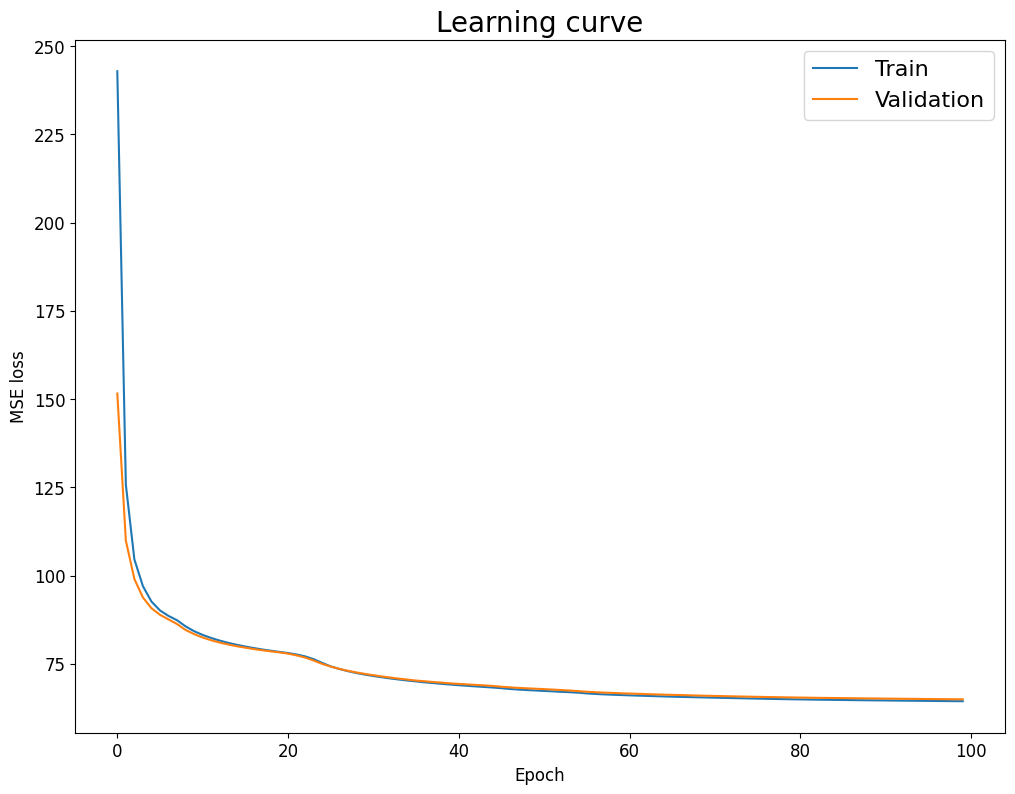

In [10]:
# Plot the learning curves

fig = plt.figure(figsize=(12, 9))

plt.plot(history['training_loss'], label='Train')
plt.plot(history['validation_loss'], label='Validation')
plt.xlabel('Epoch', size=12)
plt.ylabel('MSE loss', size=12)
plt.title('Learning curve')
plt.legend()

On the plot, we are able to observe that the MSE loss has a sharpe decline within the first several epochs. At Epoch 50, the losses of trained and validation start to coincide. The MSE loss became stable after 40 epochs, which means that the model successfully decreased the loss and became more accurate.

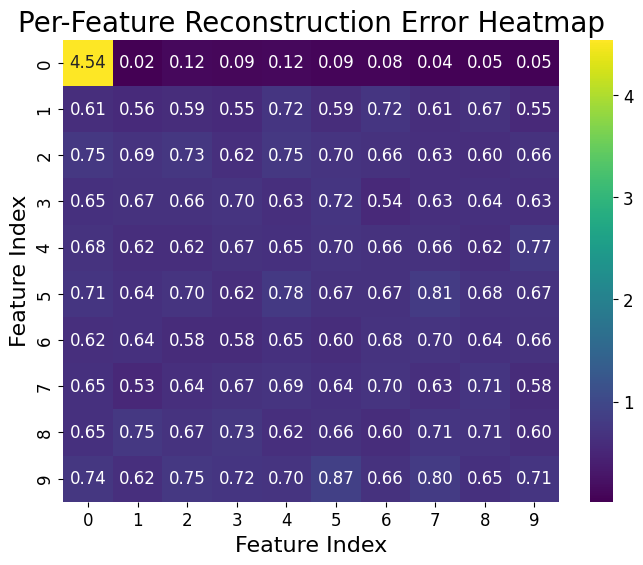

In [11]:
errors = []
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        err = (inputs.flatten(start_dim=1) - outputs.flatten(start_dim=1)) ** 2
        errors.append(err)
errors = np.vstack(errors)
mse = np.mean(errors, axis=0)
mse_matrix = mse.reshape((10, 10))

plt.figure(figsize=(8, 6))
sns.heatmap(mse_matrix, annot=True, fmt=".2f", cmap="viridis")
plt.title("Per-Feature Reconstruction Error Heatmap")
plt.xlabel("Feature Index")
plt.ylabel("Feature Index")
plt.show()

Most values are low (dark colors), meaning reconstruction is mostly accurate.
The top-left cell (4.54) is very bright (yellow), meaning this feature had the highest reconstruction error. However, the the first other 9 features, it makes precise prediction. For the remaining features, the odd number features mostly produce a better reconstruction, and the even number features mostly have a slightly worse reconstruction, with higher errors.

<a name="task-12"></a>

## (1.2) [(index)](#index-task-12)

For problem 1.2 we select the first three models of the model produced above.

In [12]:
# Select the first three models as encoders
encoder_model = model[:5]
print(encoder_model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
)


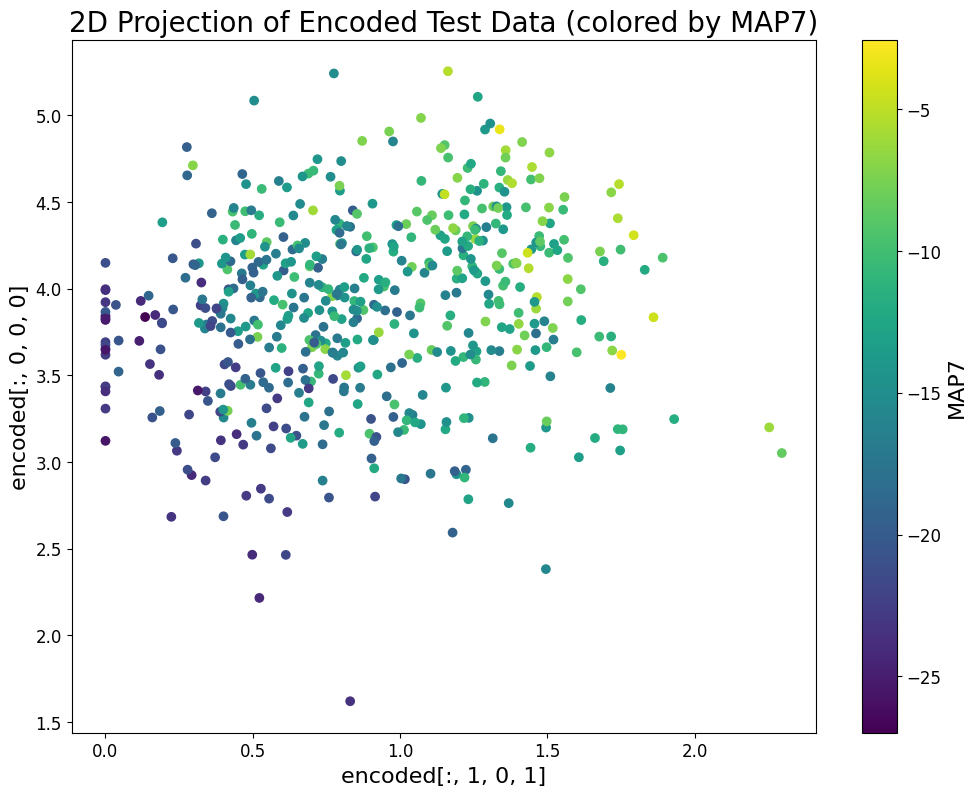

In [13]:
x_list = []
y_list = []

# Produce the [1, 0 ,1] and [0, 0, 0] models
encoder_model.eval()
with torch.no_grad():
    for batch_inputs, labels in test_loader:
        encoded = encoder_model(batch_inputs)

        x_vals = encoded[:, 1, 0, 1].cpu()
        y_vals = encoded[:, 0, 0, 0].cpu()

        x_list.append(x_vals)
        y_list.append(y_vals)

x_coords = torch.cat(x_list, dim=0).numpy()
y_coords = torch.cat(y_list, dim=0).numpy()

plt.figure(figsize=(12, 9))
scatter = plt.scatter(x_coords, y_coords, c=map7_test_tensor, cmap='viridis')
plt.colorbar(scatter, label='MAP7')
plt.xlabel('encoded[:, 1, 0, 1]')
plt.ylabel('encoded[:, 0, 0, 0]')
plt.title('2D Projection of Encoded Test Data (colored by MAP7)')
plt.show()


In [14]:
# Get the results from the encoder model for trained, validation and testing sets, then convert them into pytorch
encoder_model.eval()
encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in train_loader:
        encoded = encoder_model(batch_inputs)

        encoded_list.append(encoded)

encoded_all = torch.cat(encoded_list, dim=0).cpu()
encoded_trained = encoded_all.view(encoded_all.size(0), -1)

encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in val_loader:
        encoded = encoder_model(batch_inputs)

        encoded_list.append(encoded)

encoded_all = torch.cat(encoded_list, dim=0).cpu()
encoded_val = encoded_all.view(encoded_all.size(0), -1)

encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in test_loader:
        encoded = encoder_model(batch_inputs)

        encoded_list.append(encoded)

encoded_all = torch.cat(encoded_list, dim=0).cpu()
encoded_test = encoded_all.view(encoded_all.size(0), -1)

In [15]:
# Creating training and validation datasets
train_map_dataset = TensorDataset(encoded_trained, map7_train_tensor)
val_map_dataset = TensorDataset(encoded_val, map7_val_tensor)
test_map_dataset = TensorDataset(encoded_test, map7_test_tensor)

# Creating corresponding DataLoaders
train_map_loader = DataLoader(train_map_dataset, batch_size=32, shuffle=False)
val_map_loader = DataLoader(val_map_dataset, batch_size=32, shuffle=False)
test_map_loader = DataLoader(test_map_dataset, batch_size=32, shuffle=False)

Then I defined a linear model using torch.nn.Linear, converting a 200 dimensional array into a number

In [16]:
def get_model_linear():
    """
    CNN model in PyTorch:
    - Layers are Conv1d(+ReLU), MaxPool1d, Flatten and Linear(+Softmax).
    - It features an Adam optimiser and CrossEntropyLoss criterion.

    Parameters:
        x_train (np.ndarray): Training data
        n_filters (int): Number of filters to be used in the convolutional layer
        k (int): Kernel size in the convolutional layer
        pool_size (int): MaxPool1d window size
        stride_pool (int): Stride of the MaxPool1d sliding window
        classes (List): Output classes

    Returns:
        Model, criterion and optimiser.

    """

    model = Sequential(
        Linear(200, 1)
    )
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-3) ## <-- SOLUTION

    return model, criterion, optimiser


In [17]:
linear_model, criterion, optimiser = get_model_linear() ## <-- SOLUTION
print(linear_model)

Sequential(
  (0): Linear(in_features=200, out_features=1, bias=True)
)


In [18]:
#Define an MSE loss function
def compute_mse_loss_reg(original, reconstructed):
    N = original.shape[0]
    error = (original.view(N,-1) - reconstructed.view(N,-1)) ** 2
    total_loss = torch.mean(torch.sum(error, dim=1))
    return total_loss

In [19]:
def training_loop_linear(train_loader, val_loader, max_num_epochs=100, max_patience=5):
    """
    Training loop with early stopping to monitor the validation accuracy.

    Parameters:
        train_loader (torch.utils.data.DataLoader): Training DataLoader
        val_loader (torch.utils.data.DataLoader): Validation DataLoader
        max_num_epochs (int): Maximum number of epochs
        max_patience (int): max_patience attribute of the EarlyStopping class

    Returns:
        Model, criterion and optimiser.

    """

    history = {'training_loss': [], 'validation_loss': [], 'training_accuracy': [], 'validation_accuracy': []}
    early_stopping = EarlyStopping(max_patience=max_patience)

    for epoch in range(max_num_epochs):
        linear_model.train()
        tr_loss = 0.0
        for inputs_train, value in train_map_loader:
            optimiser.zero_grad()
            outputs = linear_model(inputs_train)
            loss = compute_mse_loss_reg(outputs, value)
            loss.backward()
            optimiser.step()
            tr_loss += loss.item() * inputs_train.size(0)
        history['training_loss'].append(tr_loss / len(train_loader.dataset))

        linear_model.eval()
        val_loss = 0.0
        with torch.no_grad():
          for inputs_val, value in val_map_loader:
                outputs_val = linear_model(inputs_val)
                loss_val = compute_mse_loss_reg(value, outputs_val)
                val_loss += loss_val.item() * inputs_val.size(0)
        history['validation_loss'].append(val_loss / len(val_loader.dataset))

        print(f"Epoch {epoch+1}/{max_num_epochs}: Training Loss: {tr_loss / len(train_loader.dataset):.4f}, Validation Loss: {val_loss / len(val_loader.dataset):.4f}")

        # Early stopping check
        early_stopping.step(tr_loss / len(train_loader.dataset))
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

    return history, linear_model

In [ ]:
# Calling the training loop
max_num_epochs = 1000
max_patience = 10

history, linear_model = training_loop_linear(train_loader, val_loader, max_num_epochs, max_patience)

Epoch 1/1000: Training Loss: 57.7105, Validation Loss: 26.1421
Epoch 2/1000: Training Loss: 25.7556, Validation Loss: 26.0139
Epoch 3/1000: Training Loss: 25.3981, Validation Loss: 25.6483
Epoch 4/1000: Training Loss: 25.0371, Validation Loss: 25.2455
Epoch 5/1000: Training Loss: 24.6378, Validation Loss: 24.8099
Epoch 6/1000: Training Loss: 24.2106, Validation Loss: 24.3521
Epoch 7/1000: Training Loss: 23.7640, Validation Loss: 23.8803
Epoch 8/1000: Training Loss: 23.3046, Validation Loss: 23.4000
Epoch 9/1000: Training Loss: 22.8376, Validation Loss: 22.9153
Epoch 10/1000: Training Loss: 22.3670, Validation Loss: 22.4295
Epoch 11/1000: Training Loss: 21.8965, Validation Loss: 21.9455
Epoch 12/1000: Training Loss: 21.4287, Validation Loss: 21.4655
Epoch 13/1000: Training Loss: 20.9659, Validation Loss: 20.9914
Epoch 14/1000: Training Loss: 20.5102, Validation Loss: 20.5248
Epoch 15/1000: Training Loss: 20.0630, Validation Loss: 20.0672
Epoch 16/1000: Training Loss: 19.6255, Validation

In [ ]:
# Plot the learning curves

fig = plt.figure(figsize=(12, 9))

plt.plot(history['training_loss'], label='Train')
plt.plot(history['validation_loss'], label='Validation')
plt.xlabel('Epoch', size=12)
plt.ylabel('MSE loss', size=12)
plt.title('Learning curve')
plt.legend()

From this graph, I can observe that the MSE loss has a rapid decline during the first several epochs. From about Epoch 100, the training error and calidation error start to coincide. There is a obvious declinefor both errors, os we can conclude that our model successfully decreased the error and made it more accurate.

In [ ]:
def r_squared(y_true, y_pred):

    y_true = y_true.cpu().numpy().reshape(y_true.shape[0], -1)
    y_pred = y_pred.detach().cpu().numpy().reshape(y_pred.shape[0], -1)

    ss_total = np.sum((y_true - np.mean(y_true))**2)
    ss_residual = np.sum((y_true - y_pred)**2)

    return 1 - (ss_residual / ss_total)

In [ ]:
r_squared(map7_test_tensor, model(encoded_test))

The R Squared error is 0.688. It is positive, which means that our model produce a decent over all positive prediction for the parameter. About 69% of the data's variability is captured by the model, while the remaining 31% is due to unknown factors or noise, so the model is a good fit but still not perfect. There is still a room for improvement.

<a name="task-2"></a>

# Task 2: Graph-based learning [(index)](#index-task-2)

In [ ]:
PATH='/content/drive/MyDrive/data_science_cw2/' # Put your path to the file here

# Dataset upload #
import pandas as pd
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

X = dataset.iloc[:400, :10].values # extract the first 400 rows and 10 columns
treatment = dataset.iloc[:, 101].values[:400, ] # extract the corresponding 400 treatment labels

<a name="task-21"></a>

## (2.1) [(index)](#index-task-21)

In [ ]:
# Define cosine similarity function
def cosine_similarity(X):
  cos_sim = np.dot(X, X.T) / (np.linalg.norm(X, axis=1)[:, np.newaxis] * np.linalg.norm(X, axis=1))
  return cos_sim

In [ ]:
# Use breadth first search to find the number of connected components
def count_connected_components_bfs(adj_matrix):
    n = len(adj_matrix)
    visited = [False] * n

    def bfs(start):
        queue = deque([start])
        while queue:
            node = queue.popleft()
            for neighbor, is_connected in enumerate(adj_matrix[node]):
                if is_connected and not visited[neighbor]:
                    visited[neighbor] = True
                    queue.append(neighbor)

    count = 0
    for i in range(n):
        if not visited[i]:
            count += 1
            visited[i] = True
            bfs(i)

    return count

In [ ]:
N=400

S = cosine_similarity(X)
delta_values = np.linspace(S.min(), S.max(), 200)
num_components = []
sparsity_levels = []

# Compute connected components and sparsity levels
for delta in delta_values:
    A_delta = np.where(S >= delta, S, 0)
    np.fill_diagonal(A_delta, 0)

    n_delta = count_connected_components_bfs(A_delta)
    num_components.append(n_delta)

    num_edges = np.count_nonzero(A_delta) / 2
    max_edges = N * (N - 1) / 2
    sparsity = num_edges / max_edges
    sparsity_levels.append(sparsity)

# Find the largest delta that keeps graph connected
connected_deltas = [delta for i, delta in enumerate(delta_values) if num_components[i] == 1]
delta_star = max(connected_deltas) if connected_deltas else None

In [ ]:
def plot_graph(adjacency, x_coord, y_coord, node_size, node_color):
    """Plot undirected graph.

    Parameters:
        adjacency (np.array): N x N adjacency matrix.
        x_coord (np.array): X-coordinates for N nodes.
        y_coord (np.array): Y-coordinates for N nodes.
        node_size (np.array): Size for each of the N nodes.
        node_color (np.array): Color for each of the N nodes.
    """

    # plot
    fig, ax = plt.subplots(1)

    # plot edges
    for i in range(N):
        for j in range(i+1,N):
            if adjacency[i,j] > 0:
                ax.plot([x_coord[i],x_coord[j]],[y_coord[i],y_coord[j]], color="black", alpha=0.5, linewidth=0.3)

    # plot nodes
    scatter = ax.scatter(x_coord,y_coord,s=0.2*node_size, c=node_color, zorder=10)

    return ax

In [ ]:
import matplotlib.patches as mpatches

connected_deltas = [delta for i, delta in enumerate(delta_values) if num_components[i] == 1]
delta_star = max(connected_deltas) if connected_deltas else None

A_final = np.where(S >= delta_star, S, 0)
np.fill_diagonal(A_final, 0)

num_edges_final = np.count_nonzero(A_final) / 2
sparsity_final = num_edges_final / max_edges

# Compute normalized Laplacian matrix
## EDIT THIS CELL
d = np.sum(A_final, axis=1)
# define diagonal degree matrix
D = np.diag(d)       # <-- SOLUTION

# compute combinatorial Laplacian
L = D - A_final            # <-- SOLUTION

# compute square root of inverse diagonal degree matrix
D_sqrt_inv = np.diag(1/np.sqrt(d))   # <-- SOLUTION

# compute symmetric normalised Laplacian
L_s = D_sqrt_inv @ L @ D_sqrt_inv    # <-- SOLUTION

eigvals, eigvecs = np.linalg.eigh(L_s)

xy_pos = eigvecs[:, 1:3]

treatment_labels = treatment

node_colors = np.array(['orange' if label == 1 else 'blue' for label in treatment_labels])

fig = plt.figure(figsize=(12, 9))

plot_graph(A_final, xy_pos[:, 0], xy_pos[:, 1], np.ones(N) * 50, node_colors)

orange_patch = mpatches.Patch(color='orange', label='Label = 1')
blue_patch = mpatches.Patch(color='blue', label='Label = 0')

plt.legend(handles=[orange_patch, blue_patch], loc='upper right')

plt.xlabel("Eigenvector 2 value")
plt.ylabel("Eigenvector 3 value")
plt.title("Spectral Graph Layout")

plt.show()

In this graph, I can observe a clear seperation between the two labels with the scale of eigenvector 2 and eigenvector 3. This shows that the 2nd eigenvector and the third eigenvector produce a clear classification for the two types of the points.

In [ ]:
delta_values = np.linspace(S.min(), S.max(), 200)
num_components = []
sparsity_levels = []

# Compute connected components and sparsity levels
for delta in delta_values:
    A_delta = np.where(S >= delta, S, 0)
    np.fill_diagonal(A_delta, 0)

    n_delta = count_connected_components_bfs(A_delta)
    num_components.append(n_delta)

    num_edges = np.count_nonzero(A_delta) / 2
    max_edges = N * (N - 1) / 2
    sparsity = num_edges / max_edges
    sparsity_levels.append(sparsity)

# Find delta_star (largest delta that keeps graph connected)
connected_deltas = [delta for i, delta in enumerate(delta_values) if num_components[i] == 1]
delta_star = max(connected_deltas) if connected_deltas else None

delta_values = np.array(delta_values)
num_components = np.array(num_components)
sparsity_levels = np.array(sparsity_levels)
plt.figure(figsize=(8, 6))
plt.plot(delta_values, num_components, marker='o', linestyle='-', color='blue', markersize=3, label="Connected Components")
plt.axvline(x=delta_star, color='red', linestyle='--', linewidth=2, label=r"delta (Fully Connected)")
plt.xlabel(r"Threshold delta")
plt.ylabel("Number of Connected Components")
plt.title("Connected Components vs. Threshold delta")
plt.legend()
plt.grid(True)
plt.show()

print(f'The largest delta value for a connected graph is', delta_star)

At lower delta values, the graph is fully connected. As delta grows above the threshold value, the number of connected components rapidly increases, which means that the whole graph is separated into different parts. As the delta increases across the threshold value, the number of components increases rapidly.

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(delta_values, sparsity_levels, marker='o', linestyle='-', color='green', markersize=3, label="Sparsity Level")
plt.axvline(x=delta_star, color='red', linestyle='--', linewidth=2, label=r"delta (Fully Connected)")
plt.xlabel(r"Threshold delta")
plt.ylabel("Sparsity Level")
plt.title("Sparsity Level vs. Threshold delta")
plt.legend()
plt.grid(True)
plt.show()

At lower delta values, the network has very few connections and is mostly empty. As delta increases, more connections are added, and the network becomes less sparse. However, when delta is close to 1, the network quickly changes from having only a few connections to being almost fully connected, as shown by the red dashed line. This means there is a key point where even a small increase in delta leads to a big jump in connectivity, showing a sudden change in the network’s structure.

<a name="task-22"></a>

## (2.2) [(index)](#index-task-22)

In [ ]:
# Calculate the degree centrality of the graph
degree_A = A_final.sum(axis=1)
degree_centrality = degree_A / (2 * num_edges_final)

degree_centrality_treatment_1 = degree_centrality[treatment_labels == 1]
degree_centrality_treatment_0 = degree_centrality[treatment_labels == 0]

degree_treatment_0 = np.mean(degree_A[treatment_labels == 0])
degree_treatment_1 = np.mean(degree_A[treatment_labels == 1])

mean_degree_treatment_1 = np.mean(degree_treatment_1)
mean_degree_treatment_0 = np.mean(degree_treatment_0)

fig, ax = plt.subplots(figsize=(8, 6))

bins = "auto"
ax.hist(degree_centrality_treatment_1, bins=bins, alpha=0.5, edgecolor='black', label=r"Community 1", color="purple")
ax.hist(degree_centrality_treatment_0, bins=bins, alpha=0.5, edgecolor='black', label=r"Community 2", color="yellow")

ax.set_xlabel("Degree Centrality", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.set_title("Degree Centrality Distribution by Treatment Group", fontsize=14)
ax.legend()

plt.show()

print(f"Mean Degree Centrality for Treatment = 1: {mean_degree_treatment_1:.2f}")
print(f"Mean Degree Centrality for Treatment = 0: {mean_degree_treatment_0:.2f}")


The histogram shows a distinct difference in degree centrality distribution between the two treatment groups (Treatment = 1 and Treatment = 0). The mean degree centrality for Treatment = 1 is 38.47, whereas for Treatment = 0, it is 16.09. This suggests that nodes in the Treatment = 1 group tend to have more connections than those in the Treatment = 0 group.